In [66]:
from datasets import load_dataset
ds = load_dataset("google/civil_comments")

In [67]:
print(ds)
print(ds["train"][0])

DatasetDict({
    train: Dataset({
        features: ['text', 'toxicity', 'severe_toxicity', 'obscene', 'threat', 'insult', 'identity_attack', 'sexual_explicit'],
        num_rows: 1804874
    })
    validation: Dataset({
        features: ['text', 'toxicity', 'severe_toxicity', 'obscene', 'threat', 'insult', 'identity_attack', 'sexual_explicit'],
        num_rows: 97320
    })
    test: Dataset({
        features: ['text', 'toxicity', 'severe_toxicity', 'obscene', 'threat', 'insult', 'identity_attack', 'sexual_explicit'],
        num_rows: 97320
    })
})
{'text': "This is so cool. It's like, 'would you want your mother to read this??' Really great idea, well done!", 'toxicity': 0.0, 'severe_toxicity': 0.0, 'obscene': 0.0, 'threat': 0.0, 'insult': 0.0, 'identity_attack': 0.0, 'sexual_explicit': 0.0}


In [68]:
import pandas as pd

# Same sampling as the professor's baseline:
# take a random sample from EACH of the dataset's own partitions
train_ds = ds["train"].train_test_split(train_size=25_000, seed=42)["train"]
val_ds   = ds["validation"].train_test_split(train_size=5_000, seed=42)["train"]
test_ds  = ds["test"].train_test_split(train_size=5_000, seed=42)["train"]

train_df = train_ds.to_pandas()
val_df   = val_ds.to_pandas()
test_df  = test_ds.to_pandas()

print("Train:", len(train_df), "| Validation:", len(val_df), "| Test:", len(test_df))
train_df.head()

Train: 25000 | Validation: 5000 | Test: 5000


,text,toxicity,severe_toxicity,obscene,threat,insult,identity_attack,sexual_explicit
0,"He looked both ways, checked again to be sure it was safe, and once the coast was clear, finally called Trump a fascist.",0.166667,0.000000,0.000000,0.0,0.166667,0.000000,0.000000
1,"Well, now we know how low the ANC MPs can go. Zuptie nicked 100 Billion bucks from us, but ho hum, they have their jobs to consider which we understand and the poor and impoverished of our nation...",0.578947,0.026316,0.342105,0.0,0.473684,0.026316,0.026316
2,Another day another Liberal backtracking.,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000
3,"All of the above assumes that these officials have a conscience to begin with. However, based on extensive and ongoing experience, this is in most cases a manifestly and deeply erroneous assumpti...",0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000
4,"Great link! Enlightening, (although a bit demoralizing). Thanks xox!",0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000


# 1. Data inspection

In [69]:
# toxicity >= 0.5 -> toxic (1), otherwise not toxic (0)
for part in [train_df, val_df, test_df]:
    part["label"] = (part["toxicity"] >= 0.5).astype(int)

for name, part in [("Train", train_df), ("Validation", val_df), ("Test", test_df)]:
    print(f"{name:10} {len(part):6} comments | toxic: {part['label'].sum():5} ({part['label'].mean():.1%})")

Train       25000 comments | toxic:  2011 (8.0%)
Validation   5000 comments | toxic:   378 (7.6%)
Test         5000 comments | toxic:   391 (7.8%)


In [70]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   text             25000 non-null  object 
 1   toxicity         25000 non-null  float32
 2   severe_toxicity  25000 non-null  float32
 3   obscene          25000 non-null  float32
 4   threat           25000 non-null  float32
 5   insult           25000 non-null  float32
 6   identity_attack  25000 non-null  float32
 7   sexual_explicit  25000 non-null  float32
 8   label            25000 non-null  int64  
dtypes: float32(7), int64(1), object(1)
memory usage: 1.0+ MB


In [71]:
toxicity_columns = ["toxicity", "severe_toxicity", "obscene", "threat",
                    "insult", "identity_attack", "sexual_explicit"]
train_df[toxicity_columns].describe()

,toxicity,severe_toxicity,obscene,threat,insult,identity_attack,sexual_explicit
count,25000.000000,25000.000000,25000.000000,25000.000000,25000.000000,25000.000000,25000.000000
mean,0.104217,0.004442,0.014120,0.009349,0.082361,0.022671,0.006652
std,0.197765,0.022386,0.065243,0.048851,0.176624,0.078919,0.045674
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,0.166667,0.000000,0.000000,0.000000,0.100000,0.000000,0.000000
max,1.000000,0.400000,1.000000,1.000000,1.000000,1.000000,0.893113


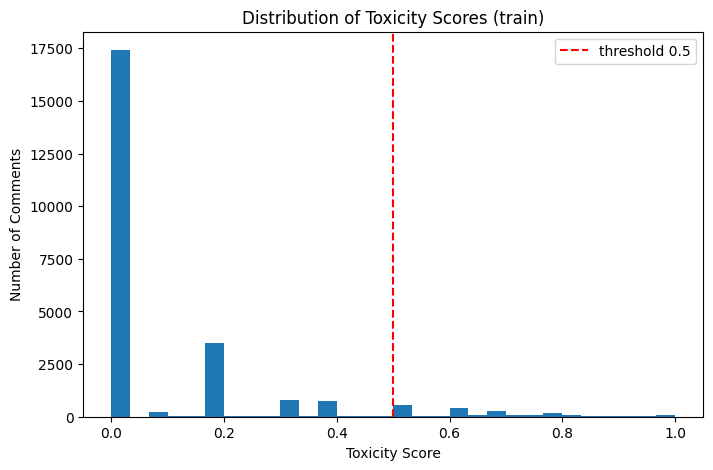

In [72]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.hist(train_df["toxicity"], bins=30)
plt.axvline(0.5, color="red", linestyle="--", label="threshold 0.5")
plt.title("Distribution of Toxicity Scores (train)")
plt.xlabel("Toxicity Score")
plt.ylabel("Number of Comments")
plt.legend()
plt.show()

## 2. Baseline model
**Representation:** TF-IDF (single words + word pairs, max 20,000 features, sublinear tf), fitted on the training set only.
**Models:** (1) majority baseline that always predicts "not toxic", (2) Logistic Regression, (3) Logistic Regression with `class_weight="balanced"` (course baseline).
**Metric:** macro-F1 (each class counts equally) plus precision/recall for the toxic class, because accuracy is misleading with imbalanced classes.

In [73]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),
    min_df=2,
    max_features=20_000,
    sublinear_tf=True
)

X_train = vectorizer.fit_transform(train_df["text"])   # learn the word list + convert
X_val   = vectorizer.transform(val_df["text"])         # only convert

y_train = train_df["label"].values
y_val   = val_df["label"].values

print("Train matrix:", X_train.shape)

Train matrix: (25000, 20000)


In [74]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

def evaluate(name, y_true, y_pred):
    print("=" * 55)
    print(name)
    print("=" * 55)
    print(classification_report(y_true, y_pred, target_names=["not toxic", "toxic"],
                                digits=3, zero_division=0))

dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
evaluate("Majority baseline (always 'not toxic')", y_val, dummy.predict(X_val))

lr = LogisticRegression(max_iter=1000, random_state=42).fit(X_train, y_train)
evaluate("TF-IDF + Logistic Regression", y_val, lr.predict(X_val))

Majority baseline (always 'not toxic')
              precision    recall  f1-score   support

   not toxic      0.924     1.000     0.961      4622
       toxic      0.000     0.000     0.000       378

    accuracy                          0.924      5000
   macro avg      0.462     0.500     0.480      5000
weighted avg      0.855     0.924     0.888      5000

TF-IDF + Logistic Regression
              precision    recall  f1-score   support

   not toxic      0.929     1.000     0.963      4622
       toxic      0.963     0.069     0.128       378

    accuracy                          0.929      5000
   macro avg      0.946     0.534     0.546      5000
weighted avg      0.932     0.929     0.900      5000



In [75]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

def evaluate(name, y_true, y_pred):
    print("=" * 55)
    print(name)
    print("=" * 55)
    print(classification_report(y_true, y_pred, target_names=["not toxic", "toxic"],
                                digits=3, zero_division=0))

dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
evaluate("Majority baseline (always 'not toxic')", y_val, dummy.predict(X_val))

lr = LogisticRegression(max_iter=1000, random_state=42).fit(X_train, y_train)
evaluate("TF-IDF + Logistic Regression", y_val, lr.predict(X_val))

Majority baseline (always 'not toxic')
              precision    recall  f1-score   support

   not toxic      0.924     1.000     0.961      4622
       toxic      0.000     0.000     0.000       378

    accuracy                          0.924      5000
   macro avg      0.462     0.500     0.480      5000
weighted avg      0.855     0.924     0.888      5000

TF-IDF + Logistic Regression
              precision    recall  f1-score   support

   not toxic      0.929     1.000     0.963      4622
       toxic      0.963     0.069     0.128       378

    accuracy                          0.929      5000
   macro avg      0.946     0.534     0.546      5000
weighted avg      0.932     0.929     0.900      5000



In [76]:
lr_bal = LogisticRegression(max_iter=1000, random_state=42, class_weight="balanced")
lr_bal.fit(X_train, y_train)

evaluate("TF-IDF + Logistic Regression (balanced) – course baseline", y_val, lr_bal.predict(X_val))

TF-IDF + Logistic Regression (balanced) – course baseline
              precision    recall  f1-score   support

   not toxic      0.963     0.932     0.947      4622
       toxic      0.402     0.561     0.468       378

    accuracy                          0.904      5000
   macro avg      0.682     0.746     0.707      5000
weighted avg      0.920     0.904     0.911      5000



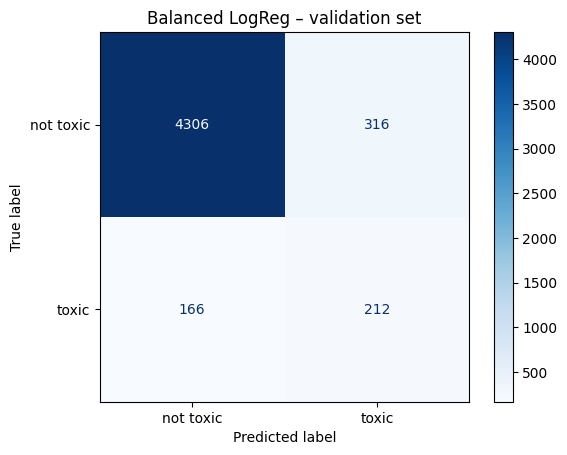

In [77]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_val, lr_bal.predict(X_val),
    display_labels=["not toxic", "toxic"], cmap="Blues"
)
plt.title("Balanced LogReg – validation set")
plt.show()

### Baseline results (validation set, 5,000 comments, 378 toxic)
| Model | Accuracy | Toxic precision | Toxic recall | Macro-F1 |
|---|---|---|---|---|
| Majority baseline | 0.924 | 0.000 | 0.000 | 0.480 |
| TF-IDF + LogReg | 0.929 | 0.963 | 0.069 | 0.546 |
| TF-IDF + LogReg (balanced) – course baseline | 0.904 | 0.402 | 0.561 | **0.707** |

**Interpretation:**
- Accuracy is misleading: the majority baseline reaches 92.4% while finding no toxic comment.
- Without class weighting, Logistic Regression rarely predicts "toxic" (recall 0.069).
- Class weighting (`balanced`) raises toxic recall to 0.561 and macro-F1 to 0.707, at the cost of more false alarms (precision 0.402).
- Even the balanced model misses ~44% of toxic comments, so it cannot moderate alone. This motivates the human-in-the-loop parts of the project.

The balanced model trained on **all 25,000 labeled comments** (macro-F1 = 0.707) serves as the **reference ("full-data") performance** for the Active Learning experiments below.

# 3. Error analysis

In [78]:
pd.set_option("display.max_colwidth", 200)

val_df["pred"] = lr_bal.predict(X_val)
val_df["prob_toxic"] = lr_bal.predict_proba(X_val)[:, 1].round(2)

missed       = val_df[(val_df["label"] == 1) & (val_df["pred"] == 0)]
false_alarms = val_df[(val_df["label"] == 0) & (val_df["pred"] == 1)]

print("MISSED toxic comments:", len(missed))
display(missed[["text", "toxicity", "prob_toxic"]].head(10))

print("FALSE ALARMS:", len(false_alarms))
display(false_alarms[["text", "toxicity", "prob_toxic"]].head(10))

MISSED toxic comments: 166


,text,toxicity,prob_toxic
7,"The Chimp has spoken.\n\nHey Chimp, are you in the new Planet of the Apes installment?",0.800000,0.26
23,"Earl - The mother lives in Mission BC (as of August 2016). Cooper is an MP from Edmonton. Did the mother move into his riding? (this is a serious question, I don't know)\n\nIf that is the c...",0.700000,0.46
52,Perhaps we did fail the lad. Children's Aid should have plucked the boy away from his obviously unfit family before they dragged him off to a warzone and taught him bombmaking. If the Children's...,0.500000,0.30
120,"My apologies; I meant you wimps, milquetoasts, and whiners.",0.645161,0.28
171,"Thumpers don't read the bible, they just thump it and wag their finger.",0.500000,0.25
228,When your read the literature from save or city! I dare Kirk or lex to say anything is not true .. everything is based on facts it refers to city issues and you can find what they say in the news...,0.584615,0.39
244,"Excellent attempt to divert the discussion from the failure of the One True Church to take effective steps to protect children. Since it is not possible to defend the defense of pedophiles, chang...",0.600000,0.09
305,"If ""Mr."" Reese has a problem with ""celibate old men"", why should we listen to this ""old"", cranky, modernist Jesuit {redundant?} at all? The Church has a ""problem"" with young people because---wait ...",0.800000,0.46
459,Again Pandora - it is you who are talking nonsense. Slaves were forced into this work and not allowed the same opportunities as white people in our country. This work if done by the slaves with ...,0.500000,0.27
473,Where's the incredibly attractive Janet Reno when you REALLY need her? She'd burn him alive as if he were a christian from Waco.,0.500000,0.45


FALSE ALARMS: 316


,text,toxicity,prob_toxic
2,Just like every soldier that prayed when landing on the shores during D-day. When you go through such horror your praying to a higher entity. I can only assume when it comes to standing up for thi...,0.000000,0.68
54,"You also need to realize that abortion is not fundamental. You are not suggesting the unborn receive equal rights to the born, you are suggesting they get more rights than the mother. You are de...",0.166667,0.57
60,"KPMG primarily wanted to salvage their own license, reputation and business interests in the country. So they did what Mr. Rupert told them. He is after all the real white mafia godfather controll...",0.000000,0.53
67,"First of all, if you are taking the GO in Toronto, you are now paying hundreds of dollars of more in taxes. Secondly, less people will buy monthly public transit passes causing city transit reven...",0.166667,0.55
84,"Papa always said we can't help the ignorance in some folk, but we can rise above it.\n\nBy welcoming all people.",0.200000,0.50
115,Kudos Donald for another election promise kept and giving the UN agenda 21 wealth redistribution scam and the “Church of Climate Blame” a kick in the junk from which they hopefully may never recov...,0.300000,0.52
117,Are Trump’s alledged voters back on the scene? O’leary is a nut job just like his idol down in the US.,0.300000,0.61
128,Exactly on point CKMSurf. Enjoy your knowledgeable posts. The other things is listening to Mufi is what got us all in this mess in the first place.,0.000000,0.51
135,You're talking nonsense. Russia didn't invade Ukraine.,0.400000,0.55
144,The best thing about Trump is that he is not Hillary.,0.000000,0.55


In [79]:
val_df["model_unsure"]    = val_df["prob_toxic"].between(0.3, 0.7)
val_df["humans_disagree"] = val_df["toxicity"].between(0.3, 0.7)
val_df["correct"]         = val_df["label"] == val_df["pred"]

summary = val_df.groupby("correct")[["model_unsure", "humans_disagree"]].mean().round(2)
summary.index = ["Wrong predictions", "Correct predictions"]
print("Share of comments where...")
summary

Share of comments where...


,model_unsure,humans_disagree
Wrong predictions,0.72,0.49
Correct predictions,0.23,0.08


# 4. Active Learning: which comments should humans label next?

**Simulation:** the 25,000 training comments form an unlabeled pool. Their reference labels act as a simulated annotator (oracle) and are revealed only after a comment is selected.

**Experimental setup (identical for all strategies):**
- Model: TF-IDF + Logistic Regression (`class_weight="balanced"`), same as the baseline
- Initial labeled set: 200 comments, stratified by label (~8% toxic)
- Batch size: 50 comments per round, annotation budget: 1,000 labels (20 rounds)
- Evaluation: macro-F1 (main metric) and toxic recall on the same validation set (5,000 comments)
- Repetitions: 5 seeds (42–46), each with a different initial labeled set

**Acquisition strategies:**
- **Random:** baseline for comparison.
- **Uncertainty (least confidence):** comments whose predicted probability is closest to 0.5. In binary classification, least confidence, margin and entropy produce the same ranking, so one of them is sufficient.
- **Diversity (farthest-first):** builds a batch whose comments are maximally different from each other in TF-IDF space (Lab 04).
- **Representative (relative representativeness):** comments similar to many pool comments but not to the labeled set (Lab 04).

In [80]:
import numpy as np
from sklearn.base import clone
from sklearn.metrics import f1_score, recall_score
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import train_test_split

SEEDS = [42, 43, 44, 45, 46]   # 5 repetitions
INITIAL_SIZE = 200             # labels we start with
BATCH_SIZE = 50                # labels asked per round
ANNOTATION_BUDGET = 1000       # extra labels in total
N_ROUNDS = ANNOTATION_BUDGET // BATCH_SIZE

# Same model as the course baseline
base_model = LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42)

STRATEGIES = ["random", "uncertainty", "diversity", "representative"]

print("Rounds:", N_ROUNDS, "| Final labeled size:", INITIAL_SIZE + ANNOTATION_BUDGET)

Rounds: 20 | Final labeled size: 1200


In [81]:
# UNCERTAINTY: higher score = model less sure
def least_confidence(probs):
    return 1 - np.max(probs, axis=1)

def acquire_uncertainty(model, X_pool, batch_size):
    scores = least_confidence(model.predict_proba(X_pool))
    return np.argsort(-scores, kind="stable")[:batch_size]

#  NOVELTY (helper for diversity): far away from everything already labelled
def acquire_novelty(X_labeled, X_pool, batch_size):
    sims = cosine_similarity(X_pool, X_labeled, dense_output=False)
    nearest_similarity = np.asarray(sims.max(axis=1).todense()).ravel()
    return np.argsort(-(1 - nearest_similarity), kind="stable")[:batch_size]

#  DIVERSITY: farthest-first, each new pick is far from the ones already picked
def acquire_diversity(X_labeled, X_pool, batch_size):
    first = int(acquire_novelty(X_labeled, X_pool, 1)[0])
    selected = [first]
    min_distances = 1 - cosine_similarity(X_pool, X_pool[first]).ravel()
    min_distances[first] = -np.inf
    while len(selected) < batch_size:
        next_idx = int(np.argmax(min_distances))
        selected.append(next_idx)
        new_distances = 1 - cosine_similarity(X_pool, X_pool[next_idx]).ravel()
        min_distances = np.minimum(min_distances, new_distances)
        min_distances[selected] = -np.inf
    return np.array(selected)

#  REPRESENTATIVE: common in the pool, rare in the labelled set
def acquire_representative(X_labeled, X_pool, batch_size):
    n = X_pool.shape[0]
    pool_mean = np.asarray(X_pool.mean(axis=0)).ravel()
    labeled_mean = np.asarray(X_labeled.mean(axis=0)).ravel()
    pool_support = np.asarray(X_pool @ pool_mean).ravel()
    pool_support = (n * pool_support - 1) / (n - 1)          # remove self-similarity
    labeled_support = np.asarray(X_pool @ labeled_mean).ravel()
    scores = pool_support - labeled_support
    return np.argsort(-scores, kind="stable")[:batch_size]

# One function that calls the right picker
def select_queries(strategy, model, labeled_idx, pool_idx, rng):
    X_pool, X_lab = X_train[pool_idx], X_train[labeled_idx]
    if strategy == "random":
        positions = rng.choice(len(pool_idx), BATCH_SIZE, replace=False)
    elif strategy == "uncertainty":
        positions = acquire_uncertainty(model, X_pool, BATCH_SIZE)
    elif strategy == "diversity":
        positions = acquire_diversity(X_lab, X_pool, BATCH_SIZE)
    elif strategy == "representative":
        positions = acquire_representative(X_lab, X_pool, BATCH_SIZE)
    else:
        raise ValueError(f"Unknown strategy: {strategy}")
    return pool_idx[positions]   # convert pool positions -> row numbers in X_train

In [82]:
def create_initial_pool(seed):
    """200 starting labels (same ~8% toxic share), the rest is the unlabeled pool."""
    all_idx = np.arange(X_train.shape[0])
    labeled, pool = train_test_split(all_idx, train_size=INITIAL_SIZE,
                                     stratify=y_train, random_state=seed)
    return np.sort(labeled), np.sort(pool)


def run_active_learning(strategy, seed, labeled_idx, pool_idx):
    rng = np.random.default_rng(seed)
    labeled, pool = labeled_idx.copy(), pool_idx.copy()
    results = []

    for round_num in range(N_ROUNDS + 1):
        # 1) Train a fresh model on the labels we have
        clf = clone(base_model)
        clf.fit(X_train[labeled], y_train[labeled])

        # 2) Evaluate on the validation set
        pred = clf.predict(X_val)
        results.append({
            "strategy": strategy, "seed": seed, "round": round_num,
            "n_labeled": len(labeled),
            "macro_f1": f1_score(y_val, pred, average="macro"),
            "toxic_recall": recall_score(y_val, pred),
            "toxic_share_labeled": y_train[labeled].mean(),  # how many toxic ones we collected
        })
        if round_num == N_ROUNDS:
            break

        # 3) Pick the next 50 comments, 4) "ask the human" (reveal labels), 5) update sets
        query = select_queries(strategy, clf, labeled, pool, rng)
        labeled = np.concatenate([labeled, query])
        pool = np.setdiff1d(pool, query)

    return pd.DataFrame(results)

In [83]:
import time

all_results = []
start = time.time()

for seed in SEEDS:
    labeled0, pool0 = create_initial_pool(seed)      # same start for all 4 strategies
    for strategy in STRATEGIES:
        print(f"seed {seed} | {strategy:14}", end=" ... ")
        res = run_active_learning(strategy, seed, labeled0, pool0)
        all_results.append(res)
        print(f"final macro-F1 = {res['macro_f1'].iloc[-1]:.3f}")

df_results = pd.concat(all_results, ignore_index=True)
print(f"\nDone in {(time.time() - start) / 60:.1f} minutes")

seed 42 | random         ... final macro-F1 = 0.504
seed 42 | uncertainty    ... final macro-F1 = 0.628
seed 42 | diversity      ... final macro-F1 = 0.510
seed 42 | representative ... final macro-F1 = 0.515
seed 43 | random         ... final macro-F1 = 0.506
seed 43 | uncertainty    ... final macro-F1 = 0.663
seed 43 | diversity      ... final macro-F1 = 0.513
seed 43 | representative ... final macro-F1 = 0.514
seed 44 | random         ... final macro-F1 = 0.527
seed 44 | uncertainty    ... final macro-F1 = 0.641
seed 44 | diversity      ... final macro-F1 = 0.529
seed 44 | representative ... final macro-F1 = 0.526
seed 45 | random         ... final macro-F1 = 0.525
seed 45 | uncertainty    ... final macro-F1 = 0.630
seed 45 | diversity      ... final macro-F1 = 0.524
seed 45 | representative ... final macro-F1 = 0.518
seed 46 | random         ... final macro-F1 = 0.500
seed 46 | uncertainty    ... final macro-F1 = 0.641
seed 46 | diversity      ... final macro-F1 = 0.516
seed 46 | re

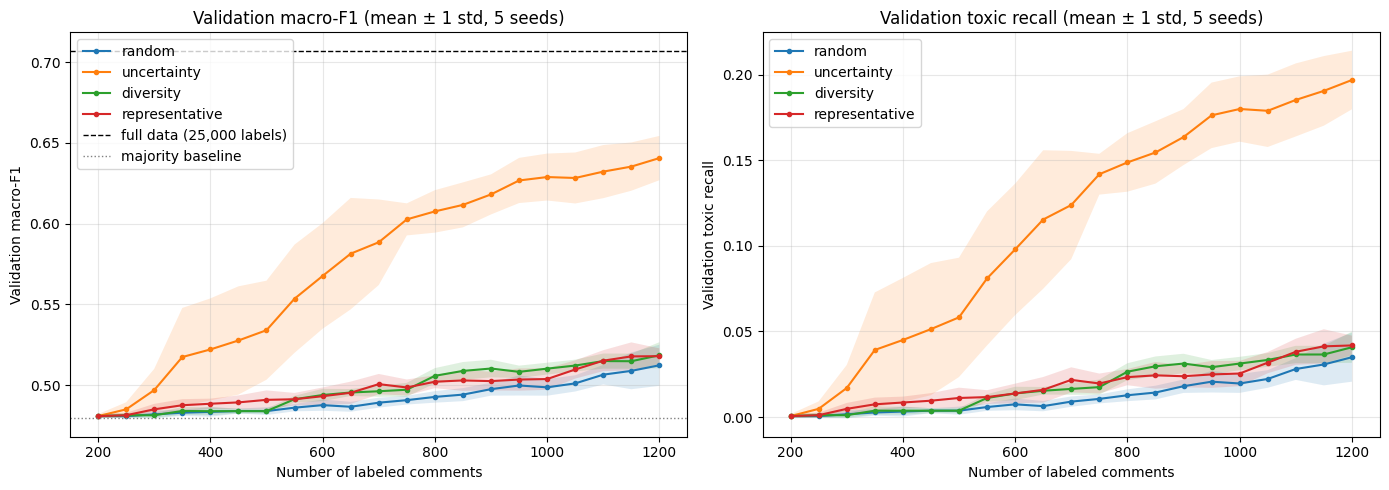

In [84]:
summary = (df_results
           .groupby(["strategy", "n_labeled"])[["macro_f1", "toxic_recall"]]
           .agg(["mean", "std"])
           .reset_index())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, metric, title in zip(axes, ["macro_f1", "toxic_recall"],
                             ["Validation macro-F1", "Validation toxic recall"]):
    for strategy in STRATEGIES:
        s = summary[summary["strategy"] == strategy]
        x = s["n_labeled"].to_numpy()
        mean = s[(metric, "mean")].to_numpy()
        std = s[(metric, "std")].to_numpy()
        ax.plot(x, mean, marker="o", markersize=3, label=strategy)
        ax.fill_between(x, mean - std, mean + std, alpha=0.15)
    ax.set_xlabel("Number of labeled comments")
    ax.set_ylabel(title)
    ax.set_title(f"{title} (mean ± 1 std, 5 seeds)")
    ax.grid(alpha=0.3)

# Reference lines on the macro-F1 plot
axes[0].axhline(0.707, color="black", linestyle="--", linewidth=1, label="full data (25,000 labels)")
axes[0].axhline(0.480, color="gray", linestyle=":", linewidth=1, label="majority baseline")
axes[0].legend()
axes[1].legend()
plt.tight_layout()
plt.show()

In [85]:
final = df_results[df_results["round"] == N_ROUNDS]
curve_avg = df_results.groupby(["strategy", "seed"])["macro_f1"].mean().reset_index()

table = pd.DataFrame({
    "final macro-F1 (mean)":  final.groupby("strategy")["macro_f1"].mean(),
    "final macro-F1 (std)":   final.groupby("strategy")["macro_f1"].std(),
    "final toxic recall":     final.groupby("strategy")["toxic_recall"].mean(),
    "avg macro-F1 over curve": curve_avg.groupby("strategy")["macro_f1"].mean(),
    "toxic share in labeled set": final.groupby("strategy")["toxic_share_labeled"].mean(),
}).loc[STRATEGIES].round(3)

table.sort_values("final macro-F1 (mean)", ascending=False)

,final macro-F1 (mean),final macro-F1 (std),final toxic recall,avg macro-F1 over curve,toxic share in labeled set
strategy,,,,,
uncertainty,0.641,0.014,0.197,0.576,0.423
diversity,0.519,0.008,0.041,0.498,0.063
representative,0.518,0.005,0.042,0.498,0.074
random,0.512,0.013,0.035,0.492,0.076


# Results

| Strategy | Final macro-F1 (mean ± std) | Final toxic recall | Avg macro-F1 over curve | Toxic share in labeled set |
|---|---|---|---|---|
| **Uncertainty** | **0.641 ± 0.014** | **0.197** | **0.576** | **42.3%** |
| Diversity | 0.519 ± 0.008 | 0.041 | 0.498 | 6.3% |
| Representative | 0.518 ± 0.005 | 0.042 | 0.498 | 7.4% |
| Random | 0.512 ± 0.013 | 0.035 | 0.492 | 7.6% |

Reference: full training data (25,000 labels) = 0.707 macro-F1; majority baseline = 0.480.

### Discussion
- **Uncertainty sampling clearly outperforms random sampling** throughout the whole learning curve and in all 5 repetitions; the variability bands do not overlap. With 1,200 labels (~5% of the pool) it reaches ~91% of the full-data macro-F1 (0.641 vs. 0.707), while random sampling stays close to the majority baseline (0.512).
- **Diversity and representative sampling perform only marginally better than random.** Their small advantage over random is within roughly one standard deviation.
- **Why?** The class imbalance is the key factor. Random, diversity and representative sampling collect toxic comments at roughly their natural rate (6–8%), so after 1,200 labels the model has seen only ~75–95 toxic examples. Uncertainty sampling selects comments near the decision boundary, which are much more often toxic: its labeled set becomes ~42% toxic. In effect, uncertainty sampling also **re-balances the training data**.
- Diversity sampling even collects *fewer* toxic comments than random (6.3%): in TF-IDF space, the "most different" comments tend to be unusual texts (rare words, very short or very long), not toxic ones.
- **Value of Active Learning for our project:** for an imbalanced moderation task, targeting human labeling effort with model uncertainty is clearly worthwhile; purely similarity-based strategies (with TF-IDF) are not.

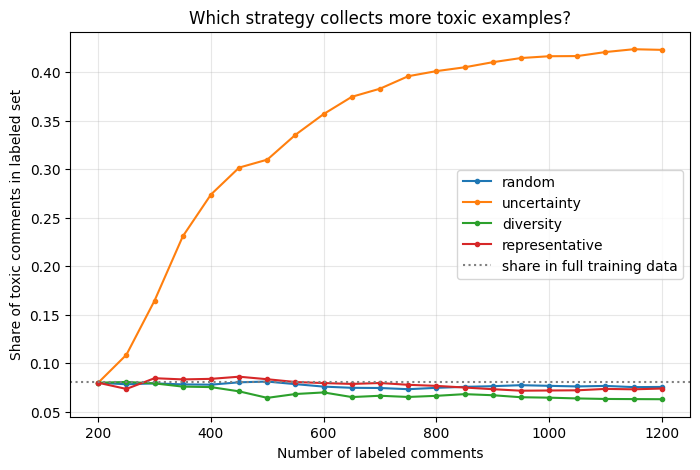

In [86]:
plt.figure(figsize=(8, 5))
for strategy in STRATEGIES:
    s = df_results[df_results["strategy"] == strategy].groupby("n_labeled")["toxic_share_labeled"].mean()
    plt.plot(s.index, s.values, marker="o", markersize=3, label=strategy)
plt.axhline(train_df["label"].mean(), color="gray", linestyle=":", label="share in full training data")
plt.xlabel("Number of labeled comments")
plt.ylabel("Share of toxic comments in labeled set")
plt.title("Which strategy collects more toxic examples?")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Limitations
- **Simulated, noise-free oracle:** the reference labels are treated as perfect, but they come from aggregated crowd ratings. Our error analysis showed that annotators often disagree on borderline comments, exactly the comments uncertainty sampling selects. Real annotation of these comments would likely be slower and less reliable.
- **Low toxic recall:** even the best strategy only reaches 0.197 toxic recall after 1,200 labels (vs. 0.561 with all data). The fixed decision threshold (0.5) and default regularization were not tuned for small labeled sets.
- **Representation:** diversity and representative sampling depend on TF-IDF similarity, which captures shared words rather than meaning. Results might differ with sentence embeddings.
- **Initial set:** the 200 initial comments are stratified using the true labels (oracle), which would not be possible in a real setting.
- **Single setup:** one dataset sample, one model, one batch size (50) and budget (1,000). The validation set was used for all comparisons; the test set remains untouched for the final evaluation.

### Conclusion
Uncertainty sampling is the most label-efficient strategy for our content-moderation task: it reaches 0.641 macro-F1 with 1,200 labels, compared with 0.512 for random sampling, consistently across 5 repetitions. Diversity and representative sampling with TF-IDF give no meaningful benefit over random. The main reason is the class imbalance: uncertainty sampling finds far more toxic examples for the annotators to label.